<a href="https://colab.research.google.com/github/elijahschoeniger-cpu/Walmart-Project-1-/blob/main/notebooks/team_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Walmart Hurricane Analytics: Hurricane Helene, September 2024
### DS2002 Midterm Project · Team Case Crushers
**Sophie Li · Eli Schoeniger · AJ Amos**

We clean five messy Walmart data files, join them to real weather from the Open-Meteo API, and answer five questions about how Florida shoppers reacted to Hurricane Helene (landfall Sept 26, 2024). We end with a recommendation for Walmart leadership and a careful reflection from all the team members.

##1. Setup

In [28]:
import os, time, sqlite3
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

# Get the data
!git clone https://github.com/elijahschoeniger-cpu/Walmart-Project-1-.git

# Hurricane Helene landfall date, used for the analysis windows and the charts
LANDFALL = pd.Timestamp('2024-09-26')

fatal: destination path 'Walmart-Project-1-' already exists and is not an empty directory.


## 2. Data loading, profile, and cleaning pipeline
**Owner: Eli**

We have five files: point-of-sale transactions (about 25,000 rows), store locations (14 rows), the product catalog (45 SKUs), distribution centers (5 rows), and a SQLite database with `daily_sales_summary` and `inventory_levels`. Every file has quality problems on purpose.

The cell below loads everything, profiles the raw transactions and stores to show the mess, then cleans each table step by step. Every decision is written to the decision log.

###2.0 Paths, database connection, and decision log
Sets up the data path, the database connection, the decision log, and the `profile()` function.

In [29]:
def profile(df, name='dataset'):
    print(f'=== {name} ===')
    print(f'{len(df):,} rows x {len(df.columns)} columns')
    print()
    summary = pd.DataFrame({
        'dtype': df.dtypes.astype(str),
        'nulls': df.isnull().sum(),
        'null_pct': (100 * df.isnull().mean()).round(1),
        'distinct': df.nunique(),
    })
    print(summary)
    print()
    print('exact duplicate rows:', df.duplicated().sum())
    return summary

REPO_PATH = globals().get('REPO_PATH', '/content/Walmart-Project-1-/')
DATA = os.path.join(REPO_PATH, 'data')

conn = sqlite3.connect(os.path.join(DATA, 'inventory_and_sales.db'))
print(pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", conn))

DECISIONS = []
def log(step, decision, rows_affected):
    DECISIONS.append({'step': step, 'decision': decision, 'rows': rows_affected})
    print(f'[{step}] {decision} ({rows_affected} row(s))')

def show_log():
    return pd.DataFrame(DECISIONS)


                  name
0  daily_sales_summary
1     inventory_levels


###2.1 Load and profile the raw data
Every file is read as text so nothing gets converted by guessing; the profile shows the mess before any cleaning.



In [30]:
# Read everything as text so pandas doesn't guess types; we convert explicitly.
NA_TOKENS = ['', 'NULL', 'N/A', 'NaN', 'nan', 'NA', 'None']
raw_txn = pd.read_csv(os.path.join(DATA, 'walmart_transactions.csv'), dtype=str,
                      keep_default_na=False)
raw_stores  = pd.read_csv(os.path.join(DATA, 'store_locations.csv'), dtype=str, keep_default_na=False)
raw_catalog = pd.read_csv(os.path.join(DATA, 'product_catalog.csv'), dtype=str, keep_default_na=False)
raw_dc      = pd.read_csv(os.path.join(DATA, 'distribution_centers.csv'), dtype=str, keep_default_na=False)
raw_sales   = pd.read_sql_query('SELECT * FROM daily_sales_summary', conn)
raw_inv     = pd.read_sql_query('SELECT * FROM inventory_levels', conn)

# Profile the files read the default way, so blanks/NULL/N/A count as missing
profile(pd.read_csv(os.path.join(DATA, 'walmart_transactions.csv')), 'walmart_transactions')
profile(pd.read_csv(os.path.join(DATA, 'store_locations.csv')), 'store_locations')

=== walmart_transactions ===
25,562 rows x 8 columns

                 dtype  nulls  null_pct  distinct
transaction_id  object      0       0.0     25532
store_id        object      0       0.0        60
timestamp       object    886       3.5     23952
sku             object      0       0.0        45
product_name    object      0       0.0        63
category        object      0       0.0        37
quantity         int64      0       0.0        11
unit_price      object      0       0.0      3668

exact duplicate rows: 30
=== store_locations ===
14 rows x 8 columns

              dtype  nulls  null_pct  distinct
store_id     object      0       0.0        14
store_name   object      0       0.0        12
city         object      0       0.0        12
state        object      0       0.0         3
zip_code      int64      0       0.0        12
latitude    float64      1       7.1        11
longitude   float64      1       7.1        11
region       object      0       0.0         7

e

,dtype,nulls,null_pct,distinct
store_id,object,0,0.0,14
store_name,object,0,0.0,12
city,object,0,0.0,12
state,object,0,0.0,3
zip_code,int64,0,0.0,12
latitude,float64,1,7.1,11
longitude,float64,1,7.1,11
region,object,0,0.0,7


###2.2 Shared helpers and lookup tables (SKUs Consolidation)
Shared cleaning functions plus the SKU map (45 SKUs → 20 products) and category map (37 spellings → 10).

In [31]:
def to_na(s):
    """Strip whitespace and turn every missing-value spelling into a real NaN."""
    s = s.astype(str).str.strip()
    return s.mask(s.isin(NA_TOKENS))

def norm_store_id(s):
    """' FL-330', 'fl_330', 'FL330' -> 'FL-330'."""
    return (s.astype(str).str.strip().str.upper()
             .str.replace(r'^FL[\s_-]?(\d{3})$', r'FL-\1', regex=True))

# 45 SKUs collapse to 20 real products (verified: every SKU's names are variants of one item)
SKU_TO_PRODUCT = {
    'PT-12': 'PT-STRAW', 'SKU#459812': 'PT-STRAW', 'POPTART-STRAW': 'PT-STRAW', 'PT_STRAWBERRY': 'PT-STRAW',
    'WTR-24': 'WATER-24', 'WATER24PK': 'WATER-24', 'WTR_24PK': 'WATER-24',
    'BATT-100': 'BATT-AA4', 'BAT-AA4': 'BATT-AA4', 'BATT_AA_4PK': 'BATT-AA4',
    'FLASH-01': 'FLASHLIGHT', 'LED-FLASH': 'FLASHLIGHT',
    'BEER-24': 'BEER-24', 'LTBEER24': 'BEER-24',
    'BG-MONO': 'MONOPOLY', 'MONOPOLY-01': 'MONOPOLY', 'GAME-MONO': 'MONOPOLY',
    'CARDS-01': 'CARDS', 'PLAYCARD-STD': 'CARDS',
    'STREAM-01': 'STREAMING', 'ROKU-STD': 'STREAMING',
    'SOUP-CAN': 'SOUP', 'CNSOUP-01': 'SOUP',
    'BREAD-WH': 'BREAD', 'WHITEBREAD': 'BREAD',
    'PB-16': 'PB-16', 'PNUTBTR-16': 'PB-16',
    'CNDL-EM': 'CANDLES', 'CANDLE-EMRG': 'CANDLES',
    'FAID-01': 'FIRSTAID', 'FIRSTAID-KIT': 'FIRSTAID',
    'CHRG-PORT': 'CHARGER', 'PORTCHARGER': 'CHARGER',
    'CHIPS-VP': 'CHIPS-VP', 'CHIPVARIETY': 'CHIPS-VP',
    'PTOWEL-6': 'PTOWEL-6', 'PAPERTOWEL6': 'PTOWEL-6',
    'TP-12': 'TP-12', 'TOILETPAPER12': 'TP-12',
    'DIAP-S3': 'DIAPERS-3', 'DIAPERS-3': 'DIAPERS-3',
    'BFORM-01': 'FORMULA', 'BABYFORMULA': 'FORMULA',
    'TARP-HD': 'TARP', 'HDTARP-01': 'TARP',
}
PRODUCTS = pd.DataFrame([
    ('PT-STRAW',  'Pop-Tarts Strawberry',     'Breakfast'),
    ('WATER-24',  'Bottled Water 24-Pack',    'Emergency'),
    ('BATT-AA4',  'AA Batteries 4-Pack',      'Emergency'),
    ('FLASHLIGHT','LED Flashlight',           'Emergency'),
    ('CANDLES',   'Emergency Candles',        'Emergency'),
    ('TARP',      'Heavy Duty Tarp',          'Emergency'),
    ('BEER-24',   'Light Beer 24-Pack',       'Alcohol'),
    ('MONOPOLY',  'Monopoly Board Game',      'Entertainment'),
    ('CARDS',     'Playing Cards',            'Entertainment'),
    ('STREAMING', 'Roku Streaming Stick',     'Electronics'),
    ('CHARGER',   'Portable Phone Charger',   'Electronics'),
    ('SOUP',      'Canned Soup',              'Grocery'),
    ('BREAD',     'White Bread',              'Grocery'),
    ('PB-16',     'Peanut Butter 16oz',       'Grocery'),
    ('FIRSTAID',  'First Aid Kit',            'Health'),
    ('CHIPS-VP',  'Chips Variety Pack',       'Snacks'),
    ('PTOWEL-6',  'Paper Towels 6-Roll',      'Household'),
    ('TP-12',     'Toilet Paper 12-Roll',     'Household'),
    ('DIAPERS-3', 'Diapers Size 3',           'Baby'),
    ('FORMULA',   'Baby Formula',             'Baby'),
], columns=['product_id', 'product', 'category_clean'])

# Messy category text -> the same 10 categories the database already uses
CATEGORY_MAP = {
    'emergency': 'Emergency', 'emergency supplies': 'Emergency',
    'grocery': 'Grocery', 'groceries': 'Grocery',
    'electronics': 'Electronics',
    'entertainment': 'Entertainment', 'games & entertainment': 'Entertainment',
    'household': 'Household', 'household essentials': 'Household',
    'baby': 'Baby', 'baby products': 'Baby',
    'breakfast': 'Breakfast', 'breakfast foods': 'Breakfast',
    'alcohol': 'Alcohol', 'alcoholic beverages': 'Alcohol',
    'snacks': 'Snacks',
    'health': 'Health', 'health & wellness': 'Health',
}
def norm_category(s):
    return s.astype(str).str.strip().str.lower().map(CATEGORY_MAP)

###2.3 Clean transactions
Only exact duplicates are removed; missing timestamps and returns are kept and flagged.

In [32]:
txn = raw_txn.copy()
n0 = len(txn)

# 2a. exact duplicates
dups = txn.duplicated().sum()
txn = txn.drop_duplicates().reset_index(drop=True)
log('txn_duplicates', 'Dropped exact duplicate rows (dup transaction_ids were all exact copies)', dups)
assert txn.transaction_id.is_unique

# 2b. store ids
before = txn.store_id.copy()
txn['store_id'] = norm_store_id(txn.store_id)
log('txn_store_id', "Normalized store_id to 'FL-###' (fixed case, spaces, '_' and missing dash)",
    (before != txn.store_id).sum())
assert txn.store_id.str.fullmatch(r'FL-\d{3}').all() and txn.store_id.nunique() == 12

# 2c. timestamps — 5 formats; parse each explicitly so nothing gets guessed wrong
ts = to_na(txn.timestamp)
n_missing_ts = ts.isna().sum()
FORMATS = ['%Y-%m-%d %H:%M:%S', '%Y-%m-%dT%H:%M:%S', '%m/%d/%Y %H:%M',
           '%m-%d-%Y %H:%M:%S', '%d-%b-%Y %H:%M']
parsed = pd.Series(pd.NaT, index=ts.index, dtype='datetime64[ns]')
for fmt in FORMATS:
    parsed = parsed.fillna(pd.to_datetime(ts, format=fmt, errors='coerce'))
unparsed = (ts.notna() & parsed.isna()).sum()
assert unparsed == 0, f'{unparsed} timestamps matched no known format'
txn['timestamp'] = parsed
log('txn_timestamp', 'Parsed 5 date formats (ISO, ISO-T, MM/DD/YYYY, MM-DD-YYYY, DD-Mon-YYYY) to datetime', len(txn) - n_missing_ts)
log('txn_timestamp_missing', "Missing timestamps (empty/NULL/N/A/NaN) set to NaT; rows KEPT for non-time questions, flagged ts_missing",
    n_missing_ts)
txn['ts_missing'] = txn.timestamp.isna()
assert txn.timestamp.dropna().between('2024-09-01', '2024-10-01').all()

# Timezone: POS times are local store time. Pensacola (FL-710) is in Central time; every other store is Eastern.
# timestamp_utc is what to join to the weather API data.
CENTRAL = {'FL-710'}
txn['tz'] = np.where(txn.store_id.isin(CENTRAL), 'America/Chicago', 'America/New_York')
txn['timestamp_utc'] = pd.concat([
    g.timestamp.dt.tz_localize(tz, ambiguous='NaT', nonexistent='NaT').dt.tz_convert('UTC')
    for tz, g in txn.groupby('tz')
]).sort_index()
log('txn_timezone', 'Localized timestamps (FL-710 Central, rest Eastern) and added timestamp_utc for the weather join',
    txn.timestamp_utc.notna().sum())
txn['date'] = txn.timestamp.dt.normalize()
txn['hour'] = txn.timestamp.dt.hour

# 2d. prices: '$8.26', ' 3.43 ' -> 8.26, 3.43
txn['unit_price'] = pd.to_numeric(txn.unit_price.str.replace(r'[$,\s]', '', regex=True), errors='raise')
log('txn_unit_price', "Stripped '$' and whitespace from unit_price, cast to float",
    raw_txn.unit_price.str.contains(r'[$\s]', regex=True).sum())

# 2e. quantity + negatives
txn['quantity'] = pd.to_numeric(txn.quantity, errors='raise').astype(int)
txn['is_return'] = txn.quantity < 0
log('txn_negative_qty', 'Negative quantities treated as returns: KEPT, flagged is_return. Demand analysis should filter quantity > 0',
    txn.is_return.sum())
txn['line_total'] = (txn.quantity * txn.unit_price).round(2)

# 2f. SKUs -> canonical product; categories from the product (not the messy text)
txn['sku'] = txn.sku.str.strip()
txn['product_id'] = txn.sku.map(SKU_TO_PRODUCT)
assert txn.product_id.notna().all(), 'unmapped SKU'
txn = txn.merge(PRODUCTS, on='product_id', how='left')
log('txn_sku_consolidation', f'Mapped {txn.sku.nunique()} SKUs / {raw_txn.product_name.nunique()} name variants -> {txn.product_id.nunique()} products',
    len(txn))

cat_from_text = norm_category(txn.category)
mismatch = (cat_from_text != txn.category_clean).sum()
assert cat_from_text.notna().all(), 'unmapped category spelling'
log('txn_category', f'Collapsed {raw_txn.category.nunique()} category spellings -> 10; product-derived category disagrees with text in {mismatch} rows',
    len(txn))
txn = txn.rename(columns={'product_name': 'product_name_raw', 'category': 'category_raw'})
txn = txn.rename(columns={'category_clean': 'category'})

print(f'\ntransactions: {n0:,} -> {len(txn):,} rows')
txn.head()

[txn_duplicates] Dropped exact duplicate rows (dup transaction_ids were all exact copies) (30 row(s))
[txn_store_id] Normalized store_id to 'FL-###' (fixed case, spaces, '_' and missing dash) (4345 row(s))
[txn_timestamp] Parsed 5 date formats (ISO, ISO-T, MM/DD/YYYY, MM-DD-YYYY, DD-Mon-YYYY) to datetime (24648 row(s))
[txn_timestamp_missing] Missing timestamps (empty/NULL/N/A/NaN) set to NaT; rows KEPT for non-time questions, flagged ts_missing (884 row(s))
[txn_timezone] Localized timestamps (FL-710 Central, rest Eastern) and added timestamp_utc for the weather join (24648 row(s))
[txn_unit_price] Stripped '$' and whitespace from unit_price, cast to float (4332 row(s))
[txn_negative_qty] Negative quantities treated as returns: KEPT, flagged is_return. Demand analysis should filter quantity > 0 (130 row(s))
[txn_sku_consolidation] Mapped 45 SKUs / 63 name variants -> 20 products (25532 row(s))
[txn_category] Collapsed 37 category spellings -> 10; product-derived category disagrees wit

,transaction_id,store_id,timestamp,sku,product_name_raw,category_raw,quantity,unit_price,ts_missing,tz,timestamp_utc,date,hour,is_return,line_total,product_id,product,category
0,TXN012636,FL-710,2024-09-24 09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,False,America/Chicago,2024-09-24 14:48:13+00:00,2024-09-24,9.0,False,3.15,PB-16,Peanut Butter 16oz,Grocery
1,TXN000759,FL-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02,False,America/New_York,2024-09-14 00:30:20+00:00,2024-09-13,20.0,False,2.02,SOUP,Canned Soup,Grocery
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47,False,America/New_York,2024-09-17 14:06:00+00:00,2024-09-17,10.0,False,20.94,TP-12,Toilet Paper 12-Roll,Household
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59,False,America/New_York,2024-09-11 10:29:08+00:00,2024-09-11,6.0,False,28.59,STREAMING,Roku Streaming Stick,Electronics
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82,False,America/New_York,2024-09-26 19:59:42+00:00,2024-09-26,15.0,False,56.46,BEER-24,Light Beer 24-Pack,Alcohol


### 2.4 Clean store locations
Two duplicate stores removed and the missing Tallahassee coordinates filled in, leaving 12 stores that match the transactions.

In [33]:
stores = raw_stores.copy()
stores['store_id'] = norm_store_id(stores.store_id)
for c in stores.columns:
    stores[c] = to_na(stores[c])
dups = stores.duplicated('store_id').sum()
stores = stores.drop_duplicates('store_id').reset_index(drop=True)
log('stores_duplicates', "Dropped duplicate stores that only differed by id format (FL239, FL_287)", dups)

bad_state = (stores.state != 'FL').sum()
stores['state'] = 'FL'
log('stores_state', "Standardized state ('Florida', 'Fla.') -> 'FL'", bad_state)

stores['zip_code'] = stores.zip_code.str.zfill(5)
stores[['latitude', 'longitude']] = stores[['latitude', 'longitude']].astype(float)
miss = stores.latitude.isna()
# Tallahassee city-center coordinates — needed for the weather API call and the map
stores.loc[stores.store_id == 'FL-619', ['latitude', 'longitude']] = [30.4383, -84.2807]
log('stores_coords', 'Filled missing lat/lon for FL-619 with Tallahassee city-center coordinates (manual lookup)', miss.sum())

stores['region'] = stores.region.str.strip().str.title()
stores['tz'] = np.where(stores.store_id.isin(CENTRAL), 'America/Chicago', 'America/New_York')
assert stores.store_id.nunique() == 12 and set(stores.store_id) == set(txn.store_id)
stores


[stores_duplicates] Dropped duplicate stores that only differed by id format (FL239, FL_287) (2 row(s))
[stores_state] Standardized state ('Florida', 'Fla.') -> 'FL' (3 row(s))
[stores_coords] Filled missing lat/lon for FL-619 with Tallahassee city-center coordinates (manual lookup) (1 row(s))


,store_id,store_name,city,state,zip_code,latitude,longitude,region,tz
0,FL-239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central,America/New_York
1,FL-105,Walmart Supercenter Tampa,Tampa,FL,33602,27.9506,-82.4572,West,America/New_York
2,FL-330,Walmart Supercenter Miami,Miami,FL,33101,25.7617,-80.1918,South,America/New_York
3,FL-412,Walmart Supercenter Jacksonville,Jacksonville,FL,32099,30.3322,-81.6557,North,America/New_York
4,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,FL,34741,28.2920,-81.4076,Central,America/New_York
5,FL-156,Walmart Supercenter Daytona Beach,Daytona Beach,FL,32114,29.2108,-81.0228,East,America/New_York
6,FL-501,Walmart Supercenter Fort Myers,Fort Myers,FL,33901,26.6406,-81.8723,West,America/New_York
7,FL-078,Walmart Supercenter Gainesville,Gainesville,FL,32601,29.6516,-82.3248,North,America/New_York
8,FL-619,Walmart Supercenter Tallahassee,Tallahassee,FL,32301,30.4383,-84.2807,Panhandle,America/New_York
9,FL-445,Walmart Supercenter St. Petersburg,St. Petersburg,FL,33701,27.7676,-82.6403,West,America/New_York


### 2.5 Clean product catalog
Missing unit costs filled with the same product's median cost; supplier and package size are unreliable, so we don't use them.

In [34]:
catalog = raw_catalog.copy()
for c in catalog.columns:
    catalog[c] = to_na(catalog[c])
catalog['product_id'] = catalog.sku.map(SKU_TO_PRODUCT)
assert catalog.product_id.notna().all()
catalog = catalog.merge(PRODUCTS, on='product_id', how='left')
catalog['category_raw'] = catalog.pop('category')
catalog = catalog.rename(columns={'category_clean': 'category', 'product_name': 'product_name_raw'})

catalog['unit_cost'] = pd.to_numeric(catalog.unit_cost)
miss = catalog.unit_cost.isna()
catalog['unit_cost_imputed'] = miss
catalog['unit_cost'] = catalog.unit_cost.fillna(catalog.groupby('product_id').unit_cost.transform('median'))
log('catalog_unit_cost', 'Missing unit_cost filled with median cost of the same product (other SKUs); flagged unit_cost_imputed', miss.sum())
log('catalog_supplier_pkg', 'supplier and package_size look random (e.g. Pop-Tarts from Roku Inc) — kept but marked unreliable, do not analyze', len(catalog))
catalog


[catalog_unit_cost] Missing unit_cost filled with median cost of the same product (other SKUs); flagged unit_cost_imputed (5 row(s))
[catalog_supplier_pkg] supplier and package_size look random (e.g. Pop-Tarts from Roku Inc) — kept but marked unreliable, do not analyze (45 row(s))


,sku,product_name_raw,subcategory,unit_cost,supplier,package_size,product_id,product,category,category_raw,unit_cost_imputed
0,PT-12,pop-tarts strawberry,NaN,1.930,Johnson & Johnson,4-pack,PT-STRAW,Pop-Tarts Strawberry,Breakfast,Breakfast Foods,False
1,SKU#459812,Strawberry Pop-Tart,Pop-Tarts,2.260,Roku Inc,4pk,PT-STRAW,Pop-Tarts Strawberry,Breakfast,Breakfast,False
2,POPTART-STRAW,Pop-Tarts Strawberry,NaN,2.110,Sara Lee,6 pack,PT-STRAW,Pop-Tarts Strawberry,Breakfast,Breakfast,False
3,PT_STRAWBERRY,pop-tarts strawberry,Pop-Tarts,2.110,Campbell's,4 pack,PT-STRAW,Pop-Tarts Strawberry,Breakfast,breakfast,True
4,WTR-24,BOTTLED WATER 24PK,Bottled,2.640,Sara Lee,1 pack,WATER-24,Bottled Water 24-Pack,Emergency,Emergency Supplies,False
5,WATER24PK,Bottled Water 24-Pack,Bottled,2.380,Sara Lee,24 pack,WATER-24,Bottled Water 24-Pack,Emergency,Emergency,False
6,WTR_24PK,Water - 24 Pack,NaN,2.080,Frito-Lay,1 pack,WATER-24,Bottled Water 24-Pack,Emergency,Emergency,False
7,BATT-100,BATTERIES AA 4PK,AA,3.935,3M Company,6 pack,BATT-AA4,AA Batteries 4-Pack,Emergency,Emergency Supplies,True
8,BAT-AA4,AA Batteries 4-Pack,AA,4.160,Kimberly-Clark,4pk,BATT-AA4,AA Batteries 4-Pack,Emergency,Emergency Supplies,False
9,BATT_AA_4PK,AA Batteries 4-Pack,AA,3.710,Anheuser-Busch,24 pack,BATT-AA4,AA Batteries 4-Pack,Emergency,Emergency,False


### 2.6 Clean distribution centers
Converted text numbers to real numbers; one missing shipping cost is left blank since 5 rows aren't enough to estimate it.

In [35]:
dc = raw_dc.copy()
for c in dc.columns:
    dc[c] = to_na(dc[c])
dc['surge_capacity_approx'] = dc.surge_capacity.str.contains('~', na=False)
dc['surge_capacity'] = pd.to_numeric(dc.surge_capacity.str.replace('~', '', regex=False))
log('dc_surge_capacity', "Removed '~' from surge_capacity ('~750' -> 750), flagged surge_capacity_approx", dc.surge_capacity_approx.sum())
for c in ['avg_daily_shipments', 'distance_to_orlando_mi', 'cost_per_shipment']:
    dc[c] = pd.to_numeric(dc[c])
log('dc_cost_missing', 'DC-BHM cost_per_shipment missing — left NaN (no defensible way to impute from 4 rows)',
    dc.cost_per_shipment.isna().sum())
dc


[dc_surge_capacity] Removed '~' from surge_capacity ('~750' -> 750), flagged surge_capacity_approx (1 row(s))
[dc_cost_missing] DC-BHM cost_per_shipment missing — left NaN (no defensible way to impute from 4 rows) (1 row(s))


,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment,surge_capacity_approx
0,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,500,1000,141,245.0,False
1,DC-ATL,Atlanta Distribution Center,Atlanta,GA,400,700,438,412.5,False
2,DC-DAL,Dallas Distribution Center,Dallas,TX,300,600,1108,687.0,False
3,DC-MIA,Miami Distribution Center,Miami,FL,350,750,235,298.0,True
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,NaN,False


### 2.7 Clean database tables
Problems that could matter for Q5 (fractional units, negative revenue, unknown SKUs) are flagged, not deleted.

In [36]:
sales = raw_sales.copy()
compact = sales.date.str.fullmatch(r'\d{8}')
sales['date'] = pd.to_datetime(sales.date, format='%Y-%m-%d', errors='coerce').fillna(
                pd.to_datetime(sales.date, format='%Y%m%d', errors='coerce'))
assert sales.date.notna().all()
log('db_sales_date', "daily_sales_summary: dates in two formats ('2024-09-12' and '20240912') parsed to datetime", compact.sum())
sales['store_id'] = norm_store_id(sales.store_id)
sales['category'] = norm_category(sales.category)
assert sales.category.notna().all()
dups = sales.duplicated(['date', 'store_id', 'category']).sum()
sales = sales.drop_duplicates(['date', 'store_id', 'category']).reset_index(drop=True)
log('db_sales_duplicates', 'daily_sales_summary: duplicate (date, store, category) rows after date fix — dropped', dups)

sales['units_fractional'] = sales.total_units % 1 != 0
sales['revenue_negative'] = sales.total_revenue < 0
log('db_sales_fractional', 'daily_sales_summary: fractional total_units (impossible for unit counts) — flagged units_fractional, kept for Q5',
    sales.units_fractional.sum())
log('db_sales_negative', 'daily_sales_summary: negative total_revenue — flagged revenue_negative, kept for Q5',
    sales.revenue_negative.sum())

inv = raw_inv.copy()
inv['date'] = pd.to_datetime(inv.date)
inv['store_id'] = norm_store_id(inv.store_id)
inv['product_id'] = inv.sku.map(SKU_TO_PRODUCT)
orphans = inv.product_id.isna()
inv['orphan_sku'] = orphans   # kept for Q5: possible SKU miscoding (e.g. LEGACY-PT)
log('db_inv_orphan_skus', f'inventory_levels: SKUs not in catalog {sorted(inv.loc[orphans, "sku"].unique())} — kept, flagged orphan_sku (use inv[~inv.orphan_sku] for normal analysis)', orphans.sum())
log('db_inv_on_order', 'inventory_levels: units_on_order missing — left NaN (unknown is not the same as 0)',
    inv.units_on_order.isna().sum())
inv['below_reorder'] = inv.units_on_hand < inv.reorder_point



[db_sales_date] daily_sales_summary: dates in two formats ('2024-09-12' and '20240912') parsed to datetime (218 row(s))
[db_sales_duplicates] daily_sales_summary: duplicate (date, store, category) rows after date fix — dropped (0 row(s))
[db_sales_fractional] daily_sales_summary: fractional total_units (impossible for unit counts) — flagged units_fractional, kept for Q5 (76 row(s))
[db_sales_negative] daily_sales_summary: negative total_revenue — flagged revenue_negative, kept for Q5 (34 row(s))
[db_inv_orphan_skus] inventory_levels: SKUs not in catalog ['LEGACY-PT', 'MISC-001', 'OLD-BATT-50', 'UNKNOWN-99'] — kept, flagged orphan_sku (use inv[~inv.orphan_sku] for normal analysis) (355 row(s))
[db_inv_on_order] inventory_levels: units_on_order missing — left NaN (unknown is not the same as 0) (626 row(s))


### 2.8 Final checks and save
Confirms every store ID and category lines up across files before the analysis starts.

In [37]:
assert txn.store_id.isin(stores.store_id).all()
assert sales.store_id.isin(stores.store_id).all() and inv.store_id.isin(stores.store_id).all()
assert set(txn.category) == set(sales.category)

OUT = os.path.join(DATA, 'clean')
os.makedirs(OUT, exist_ok=True)
txn.to_csv(os.path.join(OUT, 'transactions_clean.csv'), index=False)
stores.to_csv(os.path.join(OUT, 'stores_clean.csv'), index=False)
catalog.to_csv(os.path.join(OUT, 'catalog_clean.csv'), index=False)
PRODUCTS.to_csv(os.path.join(OUT, 'products.csv'), index=False)
dc.to_csv(os.path.join(OUT, 'distribution_centers_clean.csv'), index=False)
sales.to_csv(os.path.join(OUT, 'daily_sales_clean.csv'), index=False)
inv.to_csv(os.path.join(OUT, 'inventory_clean.csv'), index=False)
print('saved to', OUT)

saved to /content/Walmart-Project-1-/data/clean


## 3. Decision log, cleaned tables and shape check
**Owner: Eli (Decision log + cleaned tables) + Sophie (shape check)**

The decision log lists every cleaning step, what it did, and how many rows it touched. Below it, a short guide to the cleaned tables and the new columns we added, since the analysis filters on them throughout.

We end with a shape check - daily orders after cleaning. If the pipeline had a bug, it would usually show up here as a day at zero or a day at ten times normal.

###3.1 Decision log

In [38]:
pd.set_option('display.max_colwidth', None)   # show each decision in full
show_log()

,step,decision,rows
0,txn_duplicates,Dropped exact duplicate rows (dup transaction_ids were all exact copies),30
1,txn_store_id,"Normalized store_id to 'FL-###' (fixed case, spaces, '_' and missing dash)",4345
2,txn_timestamp,"Parsed 5 date formats (ISO, ISO-T, MM/DD/YYYY, MM-DD-YYYY, DD-Mon-YYYY) to datetime",24648
3,txn_timestamp_missing,"Missing timestamps (empty/NULL/N/A/NaN) set to NaT; rows KEPT for non-time questions, flagged ts_missing",884
4,txn_timezone,"Localized timestamps (FL-710 Central, rest Eastern) and added timestamp_utc for the weather join",24648
5,txn_unit_price,"Stripped '$' and whitespace from unit_price, cast to float",4332
6,txn_negative_qty,"Negative quantities treated as returns: KEPT, flagged is_return. Demand analysis should filter quantity > 0",130
7,txn_sku_consolidation,Mapped 45 SKUs / 63 name variants -> 20 products,25532
8,txn_category,Collapsed 37 category spellings -> 10; product-derived category disagrees with text in 0 rows,25532
9,stores_duplicates,"Dropped duplicate stores that only differed by id format (FL239, FL_287)",2


###3.2 Cleaned tables - Can everyone please check this and delete this once finish - SL

| Table | What it is | Key columns we added |
|---|---|---|
| `txn` | Cleaned transactions | `date` (local day), `ts_missing` (no timestamp, excluded from time analysis), `is_return` (negative quantity, excluded from demand), `product_id` (canonical product after SKU merge), `line_total` |
| `stores` | 12 stores with coordinates | `tz` (FL-710 is Central time) |
| `sales` | Database daily sales summary | `units_fractional`, `revenue_negative` (flagged for Q5) |
| `inv` | Database inventory levels | `below_reorder`, `orphan_sku` (flagged for Q5) |
| `weather_live` | Open-Meteo daily weather, Orlando | `source` (live API or fallback) |

###3.3 Shape check - Chart 1

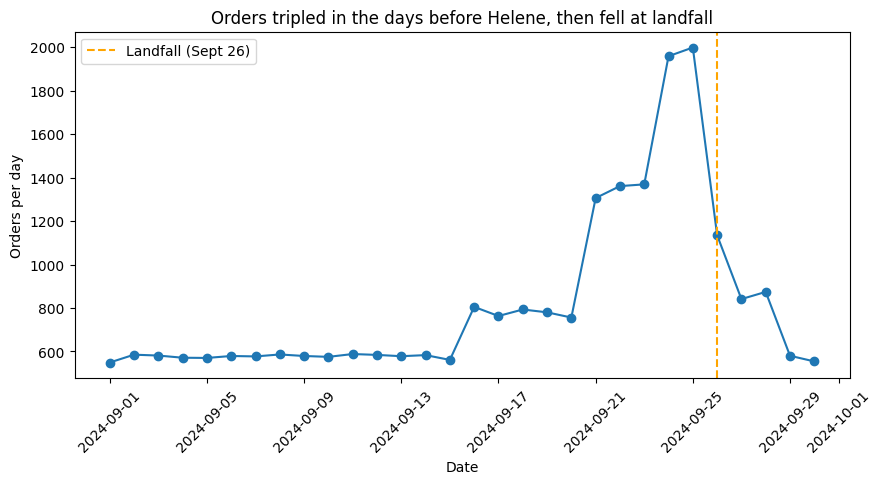

days with zero orders: 0
peak day vs Sept 1-15 baseline: 3.5 x


In [47]:
# Cleaned transactions: keep rows with a timestamp, skip returns
t = txn[~txn['ts_missing'] & ~txn['is_return']]
daily = t.groupby('date')['transaction_id'].nunique()

plt.figure(figsize=(10, 4.5))
plt.plot(daily.index, daily.values, marker='o')
plt.axvline(LANDFALL, color='orange', linestyle='--', label='Landfall (Sept 26)')
plt.xlabel('Date')
plt.ylabel('Orders per day')
plt.title('Orders tripled in the days before Helene, then fell at landfall')
plt.legend()
plt.xticks(rotation=45)
plt.show()

# A day at zero or ~10x normal would point to a pipeline bug
baseline = daily[daily.index <= '2024-09-15'].median()
print('days with zero orders:', (daily == 0).sum())
print('peak day vs Sept 1-15 baseline:', round(daily.max() / baseline, 1), 'x')

## 4. Weather API and join
**Owner: AJ**

We pull daily weather for Orlando (28.54, -81.38) from the Open-Meteo Historical Weather API (base URL: `https://archive-api.open-meteo.com/v1/archive`). The call retries on rate limits and server errors, and every row has a `source` column so a saved fallback copy is never mistaken for live data.

Weather is requested in `America/New_York` time, so each day lines up with the local sales `date`.

In [41]:
# Connect to open-meteo
import requests

BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {
        'latitude': lat, 'longitude': lon,
        'start_date': start, 'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max',
        'timezone': 'America/New_York',
    }
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()                       # any other bad status fails loudly
        frame = pd.DataFrame(r.json()['daily'])
        frame = frame.rename(columns={'time': 'date'})
        frame['date'] = pd.to_datetime(frame['date'])
        frame['source'] = 'open-meteo'
        return frame

# A saved copy of the same Open-Meteo data (Orlando, Sept 1-30, 2024) for when you have no wifi
# or the API is down. The source column says so.
FALLBACK = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=30),
    'precipitation_sum': [3.0, 12.4, 24.9, 22.1, 23.1, 9.3, 6.8, 94.7, 28.0, 14.4,
                          12.0, 0.7, 0.6, 21.1, 1.2, 7.9, 2.3, 13.3, 1.4, 0.7,
                          0.4, 2.2, 1.3, 0.3, 6.4, 15.2, 2.5, 18.0, 4.6, 3.3],
    'windspeed_10m_max': [18.8, 13.5, 22.8, 15.5, 15.2, 9.0, 14.2, 12.6, 11.5, 14.3,
                          15.8, 12.1, 10.4, 17.4, 9.0, 13.3, 12.4, 9.3, 12.9, 15.3,
                          19.9, 17.9, 16.6, 17.7, 27.2, 48.8, 45.1, 19.8, 11.7, 8.6],
    'source': 'fallback sample',
})

try:
    weather_live = daily_weather('2024-09-01', '2024-09-30')
except requests.RequestException as err:
    print('API call failed:', err)
    weather_live = FALLBACK

same = (np.allclose(weather_live['precipitation_sum'], FALLBACK['precipitation_sum'])
        and np.allclose(weather_live['windspeed_10m_max'], FALLBACK['windspeed_10m_max']))
print('source:', weather_live['source'].iloc[0])
print('matches the saved copy:', same)
weather_live.head()

source: open-meteo
matches the saved copy: False


,date,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,3.0,18.8,open-meteo
1,2024-09-02,12.4,13.5,open-meteo
2,2024-09-03,24.8,22.8,open-meteo
3,2024-09-04,22.1,15.5,open-meteo
4,2024-09-05,22.7,15.2,open-meteo


In [42]:
# WAITING TO MERGE WITH DATA FROM CLEANED DATABASES

## 5. Analysis
Five questions, each with code, a chart, and a written answer.

###5.1 Demand surge
**Owner: Eli + Sophie (Chart)**

> Which product categories experienced the greatest sales surge in the 7 days before hurricane landfall compared to the prior baseline period? Quantify the percentage increase and visualize the daily trend for the top 5 categories.

**Windows:** baseline = Sept 1–15 (flat, before the first rise on Sept 16); surge = Sept 19–25 (the 7 days before landfall on Sept 26).

###5.2 The Pop-Tarts effect (SKU consolidation)
**Owner: Eli + Sophie (Chart)**

> After standardizing all Pop-Tart SKU variants into a single product, what is the true daily sales volume? How does the uncleaned (fragmented) view compare to the cleaned (consolidated) view? What business decisions would differ between the two views?

###5.3 Weather correlation
**Owner: AJ + Sophie (Chart)**

> How do specific weather indicators (wind speed, precipitation, barometric pressure) correlate with daily sales volume across categories? Is there a detectable lag between weather severity escalation and purchasing spikes?

###5.4 Store-level geographic patterns
**Owner: AJ + Sophie (Chart)**

> Do all Florida store locations experience the same surge patterns, or do stores closer to the predicted hurricane path show earlier and larger spikes? Identify any stores that appear to be outliers.

###5.5 Signal vs. artifact
**Owner: Sophie**

> The board games/entertainment category shows a +250% sales increase. Using the SQLite inventory and sales database, investigate whether this is a genuine demand signal or a data artifact (e.g., SKU miscoding, category lumping, inventory reporting lag). Present your evidence and make a recommendation: should Walmart stock extra board games for the next storm?

## 6. Recommendation for Walmart leadership

## 7. Reflection
Each team member contributes. One solid paragraph minimum per question.

**1. Data Quality Impact**
> Describe a specific data quality issue you encountered in the supplied data. How did your cleaning decision change the outcome of your analysis? What would have happened if you had not caught it?

_TODO_

**2. ETL Trade-offs**
> You made choices about how to standardize SKUs, handle missing timestamps, and join weather data. Pick one decision and explain: what alternative approach could you have taken, and how might it have changed your results?

_TODO_

**3. Pipeline Trust**
> The Walmart CDO argued that the biggest risk is not the model — it is the pipeline. Based on your experience in this project, do you agree or disagree? What was the most fragile part of your data pipeline?

_TODO_

**4. Business vs. Data**
> For Question 5 (board games), your team had to make a recommendation with imperfect data. How did you weigh statistical evidence against business risk? Would you have decided differently with more time or more data?

_TODO_

**5. Team Collaboration**
> How did your team divide the work? What would you do differently if you had another week? What was the most valuable skill each team member contributed?

_TODO_

### The data you are getting

Five files, in the `data/` folder next to this notebook.

| File | What it is | Size |
|---|---|---|
| `walmart_transactions.csv` | Point-of-sale records from Florida stores, September 2024 | about 25,000 rows |
| `store_locations.csv` | Store details: city, coordinates, region | about 14 rows |
| `product_catalog.csv` | The master list of products and SKUs | about 45 rows |
| `distribution_centers.csv` | Distribution center capacity and shipping cost | 5 rows |
| `inventory_and_sales.db` | SQLite database with `daily_sales_summary` and `inventory_levels` | about 7,900 rows across both tables |

Every file has quality problems, and finding them is part of the work. The brief lists what to expect:

- duplicate records
- missing values written several ways: empty, `NULL`, `N/A`, NaN
- dates and times in different formats
- the same product under several SKUs and names
- inconsistent capitalization and spacing
- category names that don't match
- numbers stored as text, and prices with `$` signs
- negative quantities
- store ids written different ways across files
- weather data in a different timezone than the sales data

You will profile the transactions file in a few minutes. The database matters mostly for Question 5.

In [39]:
import sqlite3

DECISIONS = []

def log(step, decision, rows_affected):
    DECISIONS.append({'step': step, 'decision': decision, 'rows': rows_affected})
    print(f'[{step}] {decision} ({rows_affected} row(s))')

def show_log():
    return pd.DataFrame(DECISIONS)

# Get data from repository
REPO_PATH = '/content/Walmart-Project-1-/'
catalog_data = pd.read_csv(REPO_PATH + 'data/product_catalog.csv')
distribution_center = pd.read_csv(REPO_PATH + 'data/distribution_centers.csv')
walmart_transactions = pd.read_csv(REPO_PATH + 'data/walmart_transactions.csv')
store_locations = pd.read_csv(REPO_PATH + 'data/store_locations.csv')

# Read db into pandas
conn = sqlite3.connect(REPO_PATH + 'data/inventory_and_sales.db')
cursor = conn.cursor()

print(pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", conn))
pd.read_sql_query('PRAGMA table_info(inventory_levels)', conn)

                  name
0  daily_sales_summary
1     inventory_levels


,cid,name,type,notnull,dflt_value,pk
0,0,date,TEXT,0,None,0
1,1,store_id,TEXT,0,None,0
2,2,sku,TEXT,0,None,0
3,3,units_on_hand,INTEGER,0,None,0
4,4,units_on_order,INTEGER,0,None,0
5,5,reorder_point,INTEGER,0,None,0


SKU Consolidation

In [40]:
# Work on consolidating the SKUs!

API Call Code

Section for Showing Log

In [43]:
show_log()

""


###Charts (draft, pre-cleaning)

####Chart 2: Orders vs. Wind

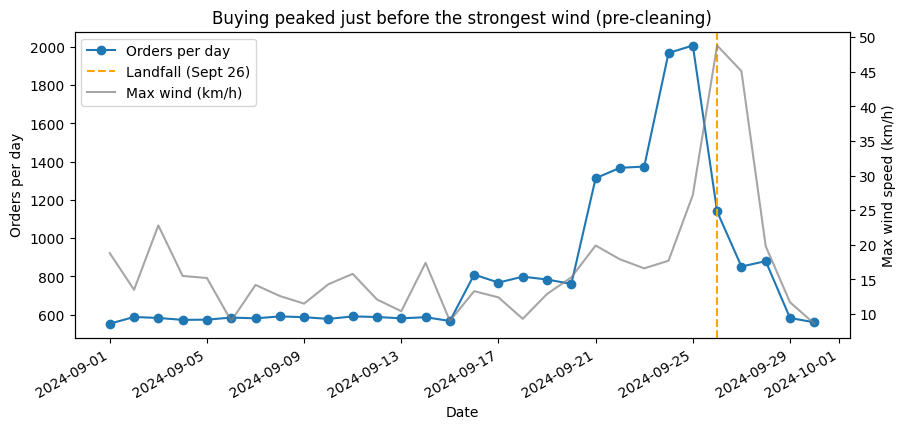

In [45]:
wind = weather_live.set_index('date')['windspeed_10m_max']

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(daily.index, daily.values, marker='o', label='Orders per day')
ax.axvline(LANDFALL, color='orange', linestyle='--', label='Landfall (Sept 26)')
ax.set_xlabel('Date')
ax.set_ylabel('Orders per day')

# Wind on a second y-axis, since it's in different units
ax2 = ax.twinx()
ax2.plot(wind.index, wind.values, color='gray', alpha=0.7, label='Max wind (km/h)')
ax2.set_ylabel('Max wind speed (km/h)')

# One legend for both lines
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left')

ax.set_title('Buying peaked just before the strongest wind (pre-cleaning)')
fig.autofmt_xdate()
plt.show()

####Chart 3: Top 5 Surging Categories

category
Breakfast        4.8
Emergency        3.5
Entertainment    3.2
Health           2.8
Alcohol          2.7
dtype: float64


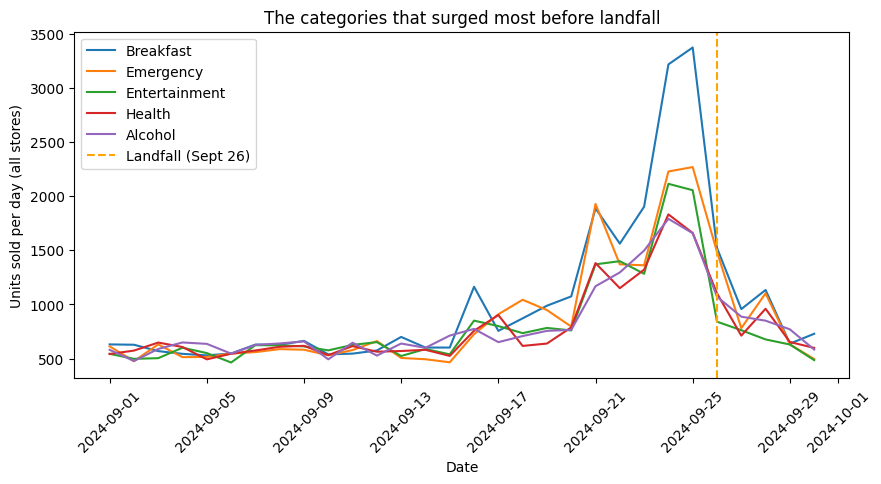

In [46]:
# Pull date, category, and units sold from the daily_sales_summary table in the database
sales_db = pd.read_sql_query('SELECT date, category, total_units FROM daily_sales_summary', conn)
sales_db['date'] = pd.to_datetime(sales_db['date'], format='mixed')   # dates come as 2024-09-12 and 20240912 - we read both

# Total units per day for each category, all stores combined
by_cat = sales_db.pivot_table(index='date', columns='category', values='total_units', aggfunc='sum')

# Derive top 5 categories by growth
growth = by_cat.loc['2024-09-23':'2024-09-25'].mean() / by_cat.loc[:'2024-09-15'].mean()
top5 = growth.sort_values(ascending=False).head(5).index
print(growth[top5].round(1))

# Plot the daily sales of top 5 categories
plt.figure(figsize=(10, 4.5))
for cat in top5:
    plt.plot(by_cat.index, by_cat[cat], label=cat)
plt.axvline(LANDFALL, color='orange', linestyle='--', label='Landfall (Sept 26)')
plt.xlabel('Date')
plt.ylabel('Units sold per day (all stores)')
plt.title('The categories that surged most before landfall')
plt.legend()
plt.xticks(rotation=45)
plt.show()